# Synthetic Concept Drift Benchmark

A feature-based synthetic electricity-demand benchmark was created to evaluate drift detection under controlled conditions. Each stream contains 20,000 half-hourly observations with time-derived features and synthetic `TOTALDEMAND`. Random noise is controlled using a fixed seed so experiments can be reproduced.

Four scenarios are generated:

- **No drift:** The relationship between the input features and `TOTALDEMAND` remains unchanged throughout the stream. This is used as a control for evaluating false detections.

- **Sudden drift:** The feature–demand relationship changes abruptly at observation 10,000. This represents an immediate regime change.

- **Gradual drift:** The relationship progressively changes between observations 9,000 and 11,000. This represents a transition where the new demand regime develops over time rather than appearing at a single instant.

- **Recurring drift:** The stream begins with Concept 1, switches to Concept 2 at observation 7,000, and returns to Concept 1 at observation 13,000. This represents a temporary regime change followed by the return of a previously observed pattern.

The generator returns both the synthetic dataset and the known changepoint indices. These known changepoints allow detector performance to be evaluated objectively using detection delay, missed detections, and false alarms.

In [5]:
%pip install matplotlib


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [7]:
from pathlib import Path
import sys

# Project root
project_root = Path.cwd().parent

# Make project root importable
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.synthetic_generator import make_feature_series

print("Synthetic generator imported successfully.")

Synthetic generator imported successfully.


In [8]:
sudden_data, sudden_cp = make_feature_series(
    kind="sudden",
    n=20000,
    noise=50,
    seed=42
)

print("Shape:", sudden_data.shape)
print("True changepoint:", sudden_cp)

print(
    "Changepoint time:",
    sudden_data.loc[sudden_cp, "SETTLEMENTDATE"]
)

sudden_data.head()

Shape: (20000, 6)
True changepoint: [10000]
Changepoint time: 10000   2018-07-28 08:30:00
Name: SETTLEMENTDATE, dtype: datetime64[us]


,SETTLEMENTDATE,hour,day_of_week,month,is_weekend,TOTALDEMAND
0,2018-01-01 00:30:00,0.5,0,1,0,1217.802396
1,2018-01-01 01:00:00,1.0,0,1,0,1148.000795
2,2018-01-01 01:30:00,1.5,0,1,0,1240.089101
3,2018-01-01 02:00:00,2.0,0,1,0,1257.250488
4,2018-01-01 02:30:00,2.5,0,1,0,1125.284381


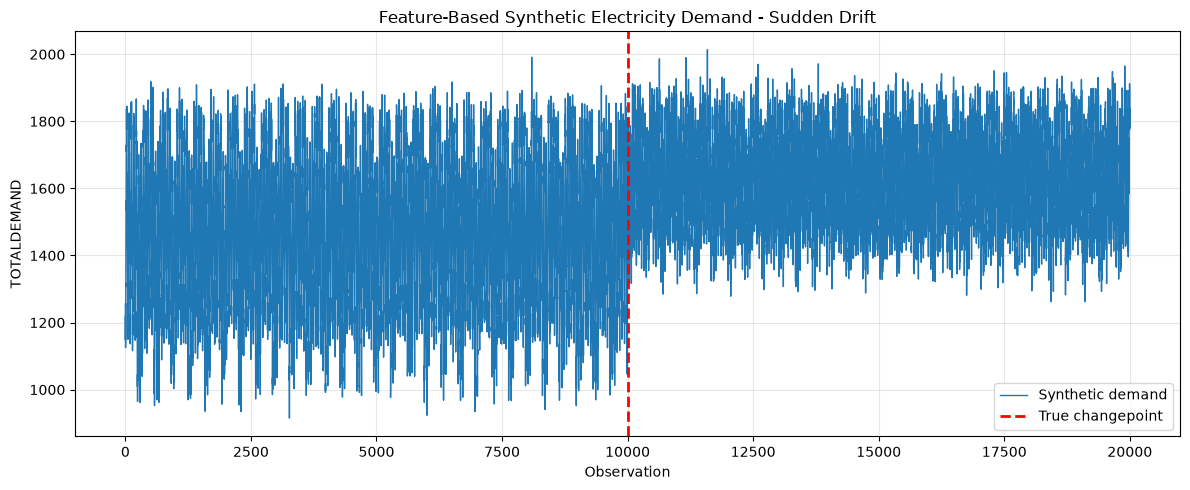

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Plot the complete synthetic demand series
plt.plot(
    sudden_data["TOTALDEMAND"].values,
    linewidth=1,
    label="Synthetic demand"
)

# Mark the true sudden changepoint
plt.axvline(
    x=sudden_cp,
    color="red",
    linestyle="--",
    linewidth=2,
    label="True changepoint"
)

plt.title("Feature-Based Synthetic Electricity Demand - Sudden Drift")
plt.xlabel("Observation")
plt.ylabel("TOTALDEMAND")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
gradual_data, gradual_cp = make_feature_series(
    kind="gradual",
    n=20000,
    noise=50,
    seed=42
)


print("Shape:", gradual_data.shape)
print("True changepoint:", gradual_cp)

print(
    "Changepoint time:",
    gradual_data.loc[gradual_cp, "SETTLEMENTDATE"]
)

gradual_data.head()

Shape: (20000, 6)
True changepoint: [9000, 11000]
Changepoint time: 9000    2018-07-07 12:30:00
11000   2018-08-18 04:30:00
Name: SETTLEMENTDATE, dtype: datetime64[us]


,SETTLEMENTDATE,hour,day_of_week,month,is_weekend,TOTALDEMAND
0,2018-01-01 00:30:00,0.5,0,1,0,1217.802396
1,2018-01-01 01:00:00,1.0,0,1,0,1148.000795
2,2018-01-01 01:30:00,1.5,0,1,0,1240.089101
3,2018-01-01 02:00:00,2.0,0,1,0,1257.250488
4,2018-01-01 02:30:00,2.5,0,1,0,1125.284381


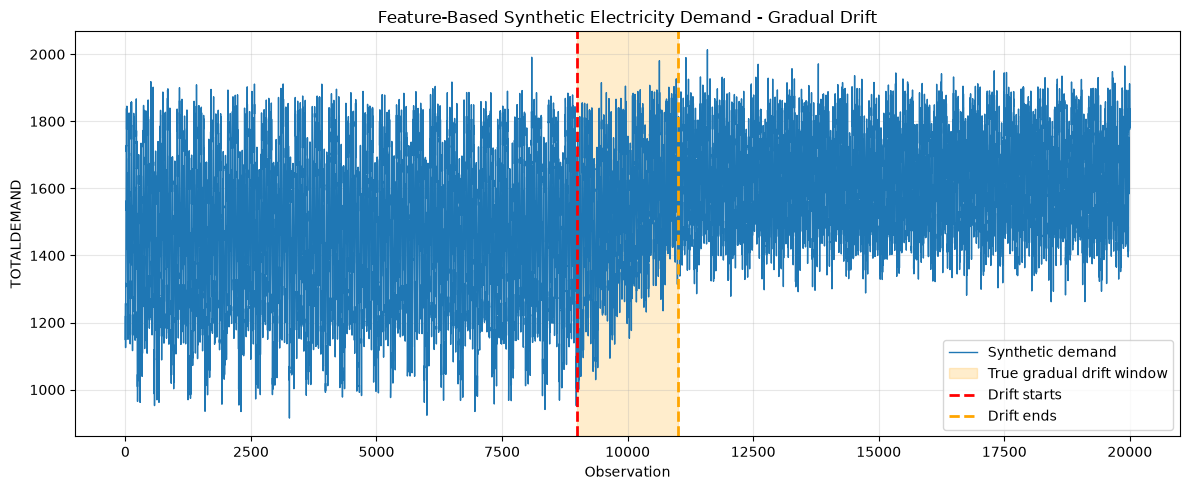

In [12]:
# Extract the gradual drift boundaries
gradual_start = gradual_cp[0]
gradual_end = gradual_cp[1]

plt.figure(figsize=(12, 5))

# Plot the synthetic demand
plt.plot(
    gradual_data["TOTALDEMAND"].values,
    linewidth=1,
    label="Synthetic demand"
)

# Shade the gradual transition window
plt.axvspan(
    gradual_start,
    gradual_end,
    alpha=0.2,
    color="orange",
    label="True gradual drift window"
)

# Mark drift start
plt.axvline(
    x=gradual_start,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Drift starts"
)

# Mark drift end
plt.axvline(
    x=gradual_end,
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Drift ends"
)

plt.title(
    "Feature-Based Synthetic Electricity Demand - Gradual Drift"
)
plt.xlabel("Observation")
plt.ylabel("TOTALDEMAND")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
recurring_data, recurring_cp = make_feature_series(
    kind="recurring",
    n=20000,
    noise=50,
    seed=42
)

print("True recurring changepoints:", recurring_cp)

for cp in recurring_cp:
    print(
        cp,
        recurring_data.loc[cp, "SETTLEMENTDATE"]
    )

True recurring changepoints: [7000, 13000]
7000 2018-05-26 20:30:00
13000 2018-09-28 20:30:00


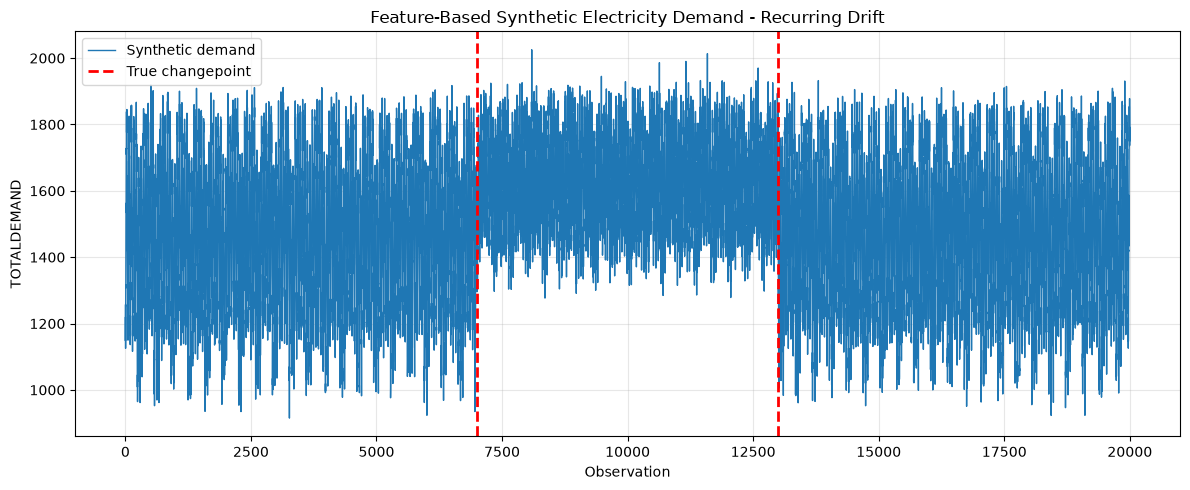

In [14]:
plt.figure(figsize=(12, 5))

# Plot the complete synthetic demand series
plt.plot(
    recurring_data["TOTALDEMAND"].values,
    linewidth=1,
    label="Synthetic demand"
)

# Mark true recurring changepoints
for i, cp in enumerate(recurring_cp):
    plt.axvline(
        x=cp,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True changepoint" if i == 0 else None
    )

plt.title("Feature-Based Synthetic Electricity Demand - Recurring Drift")
plt.xlabel("Observation")
plt.ylabel("TOTALDEMAND")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
no_drift_data, no_drift_cp = make_feature_series(
    kind="none",
    n=20000,
    noise=50,
    seed=42
)

print("True changepoints:", no_drift_cp)

True changepoints: []


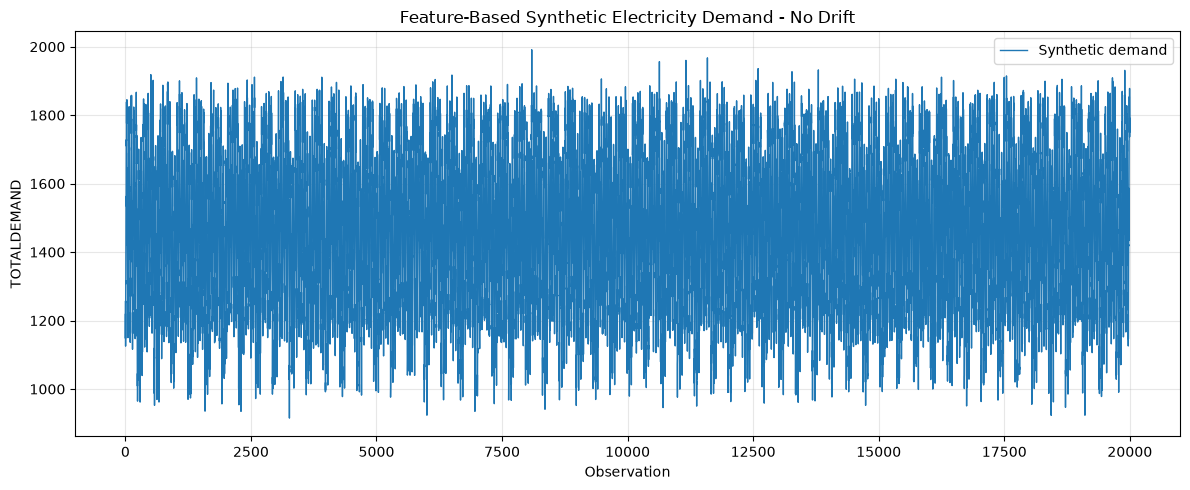

In [16]:
plt.figure(figsize=(12, 5))

plt.plot(
    no_drift_data["TOTALDEMAND"].values,
    linewidth=1,
    label="Synthetic demand"
)

plt.title("Feature-Based Synthetic Electricity Demand - No Drift")
plt.xlabel("Observation")
plt.ylabel("TOTALDEMAND")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
for kind in ["none", "sudden", "gradual", "recurring"]:

    data, changepoints = make_feature_series(
        kind=kind,
        n=20000,
        noise=50,
        seed=42
    )

    print(f"{kind.upper()}")
    print("  Shape:", data.shape)
    print("  Changepoints:", changepoints)
    print("  Missing values:", data.isna().sum().sum())
    print()

NONE
  Shape: (20000, 6)
  Changepoints: []
  Missing values: 0

SUDDEN
  Shape: (20000, 6)
  Changepoints: [10000]
  Missing values: 0

GRADUAL
  Shape: (20000, 6)
  Changepoints: [9000, 11000]
  Missing values: 0

RECURRING
  Shape: (20000, 6)
  Changepoints: [7000, 13000]
  Missing values: 0

